# Crank-Nicolson Black-Scholes solver

In this notebook I will be testing my Crank-Nicolson solver, as well as giving some exposition about the maths behind it.

I will make the assumption that the underlying stock price evolves under Geometric Brownian Motion (GBM). On the resulting Black-Scholes equation I will perform the transformation $\tau = T - t$, and the following terminal/boundary conditions:

Terminal condition: $V(S,T) = max(S-K,0)$

Boundary conditions: $V(0,t) = 0, V(S_{max},t) = S_{max} - Ke^{-r(T-t)}$

I will also take $S_{max} = 4K$, as this is large enough that the upper bound solution approaches the theoretically asymptotic value.

## Transforming the Black-Scholes equation using $\tau = T - t$

The Black-Scholes equation as it evolves from GBM: 

$$  \frac{\partial V}{\partial t} + \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + rS \frac{\partial V}{\partial S} - rV = 0. $$

Using the time to maturity variable $\tau$ this becomes (derivation in report):

$$\frac{\partial V}{\partial \tau}=\frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}+ rS \frac{\partial V}{\partial S}- rV$$

The terminal condition becomes an initial condition: $V(S,0) = \max(S-K,0)$.

The boundary conditions remain the same: $V(0,t) = 0, V(S \to \infty,t) = S - Ke^{-r\tau}$

## Spacial discretisation

The spacial domain $[0,S_{max}]$ is discretised into M uniformly spaced grid points with step size $\Delta S = \frac{S_{max}}{M}.$ The value of the numerical solution at the i-th spacial point and j-th temporal point is denoted $U_i^j \approx U(S_i,\tau_j)$. Second order accurate central finite different schemes approximate spacial derivatives:

$$\frac{\partial U}{\partial S}\biggr|_{S_i} \approx \frac{U_{i+1}^j - U_{i-1}^j}{2 \Delta S}$$

$$\frac{\partial^2 U}{\partial S^2}\biggr|_{S_i} \approx \frac{U_{i+1}^j - 2 U_i^j + U_{i-1}^j}{(\Delta S)^2}$$

## Crank-Nicolson temporal discretisation

Divide $[0,T]$ into N uniform time steps $\Delta \tau = \frac{T}{N}$. The Crank-Nicolson scheme is then formulated by defining the spacial derivative operator L from the Black-Scholes equation and by averaging this spacial differential operator over two consecutive time intervals:

$$L(U) = \frac{1}{2}\sigma^2 S^2 \frac{\partial^2 U}{\partial S^2} + rS\frac{\partial U}{\partial S} - rU$$

$$\frac{U_i^{j+1} - U_i^j}{\Delta \tau} = \frac{1}{2}\biggr[L(U_i^{j+1}) + L(U_i^j)\biggr]$$

This gives the following system of linear equations where A, B are tridiagonal coefficient matrices that depend on model parameters and grid sizes while b contains contributions from boundary conditions:

$$A U^{j+1} = B U_j + b$$


In [1]:
import sys
sys.path.append("..")

# Testing solver
from src.crank_nicolson import Crank_Nicolson_Solver

solver = Crank_Nicolson_Solver(S0=100, K=100, T=1, r=0.05, sigma=0.2, S_max=300, M=200, N=200)

price, S, V = solver.solve()

print(price)

10.454438036590371


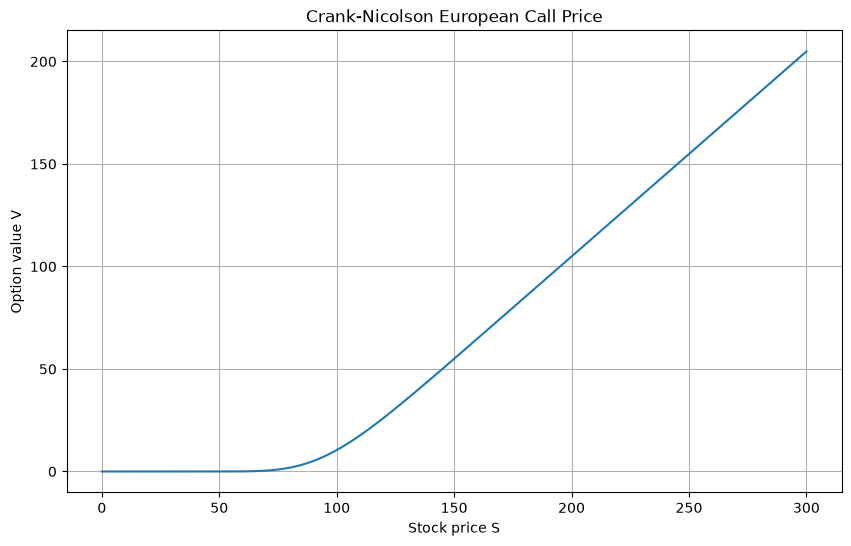

In [2]:
# Generating a plot of the option price as a function of the underlying asset price.

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(S, V)

plt.xlabel("Stock price S")
plt.ylabel("Option value V")
plt.title("Crank-Nicolson European Call Price")
plt.grid()
plt.show()

In [3]:
# Comparing the result at S=100 with the Black-Scholes formula for a European call option.

from src.analytical import call_price

bs_price = call_price(S0=100, K=100, T=1, r=0.05, sigma=0.2)# 


print(f"Analytical price:      {bs_price:.6f}")
print(f"Crank-Nicolson price:  {price:.6f}")
print(f"Absolute error:        {abs(price-bs_price):.2e}")

Analytical price:      10.450584
Crank-Nicolson price:  10.454438
Absolute error:        3.85e-03


The absolute error between my Crank-Nicolson solver and the analytical price from the solution of the Black-Scholes equation is small, indicating that it approximates the call prices well. I will now create some error and convergence plots.

In [4]:
import numpy as np

bs_values = np.zeros_like(S, dtype=float)

# Originally encountered a runtime warning when plotting the absolute error, due to dividing by zero. To fix I will consider S>0 since at S=0 the option value is zero and the absolute error is zero.

positive_S = S > 0

bs_values[positive_S] = call_price(S0=S[positive_S], K=100, T=1, r=0.05, sigma=0.2)

abs_error = abs(V - bs_values)

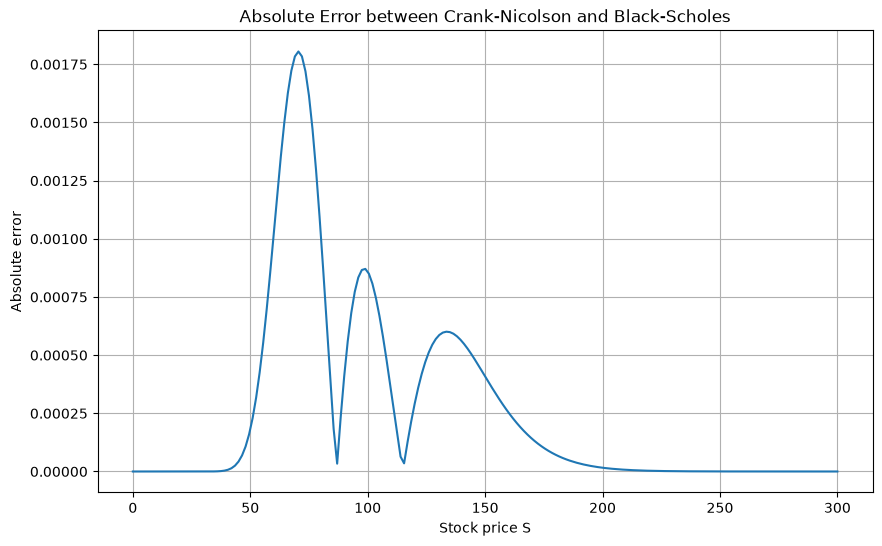

In [5]:
# Generating error plot.

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(S, abs_error)
plt.xlabel("Stock price S")
plt.ylabel("Absolute error")
plt.title("Absolute Error between Crank-Nicolson and Black-Scholes")
plt.grid()
plt.show()



In [6]:
# Generating a convergence plot by varying the grid size (M and N) and observing the absolute error at S0=100.

import pandas as pd

grid_sizes = [10, 20, 40, 80, 160, 320]

results = []

for M in grid_sizes:
    M = N = M  # Use the same value for M and N for simplicity  
    solver = Crank_Nicolson_Solver(S0=100, K=100, T=1, r=0.05, sigma=0.2, S_max=300, M=M, N=N)

    price, S, V = solver.solve()

    bs_values = np.zeros_like(S, dtype=float)
    positive_S = S > 0
    bs_values[positive_S] = call_price(S0=S[positive_S], K=100, T=1, r=0.05, sigma=0.2)

    # Computing errors.

    abs_error = abs(V - bs_values)
    max_abs_error = np.max(abs_error)
    rmse = np.sqrt(np.mean(abs_error**2))
    mae = np.mean(abs_error)
    relative_L2_error = np.linalg.norm(V - bs_values) / np.linalg.norm(bs_values)

    dS = 300 / M
    dt = 1 / N

    results.append({
        "M": M, "N" : N, "dS": dS, "dt": dt, "Max Absolute Error": max_abs_error, "RMSE": rmse, "MAE": mae, "Relative L2 Error": relative_L2_error })
    
results_df = pd.DataFrame(results)
results_df.style.format({"Max Absolute Error": "{:.6e}", "RMSE": "{:.6e}", "MAE": "{:.6e}", "Relative L2 Error": "{:.6e}"})
results_df 

,M,N,dS,dt,Max Absolute Error,RMSE,MAE,Relative L2 Error
0,10,10,30.0000,0.100000,0.337321,0.142145,0.084752,0.001374
1,20,20,15.0000,0.050000,0.185788,0.050087,0.023141,0.000498
2,40,40,7.5000,0.025000,0.039842,0.011984,0.006531,0.000121
3,80,80,3.7500,0.012500,0.011445,0.003107,0.001619,0.000032
4,160,160,1.8750,0.006250,0.002739,0.000765,0.000409,0.000008
5,320,320,0.9375,0.003125,0.000702,0.000193,0.000102,0.000002


In [ ]:
# Now I will compute the convergence rates based on the errors and grid sizes.

results_df["rmse_rate"] = np.nan
results_df["max_abs_error_rate"] = np.nan

for i in range(1, len(results_df)): # Will use the formula rate = log(error_i-1 / error_i) / log(h_i-1 / h_i) where h is the grid size (dS in this case).
    results_df.loc[i, "rmse_rate"] = np.log(results_df.loc[i-1, "RMSE"] / results_df.loc[i, "RMSE"]) / np.log(results_df.loc[i-1, "dS"] / results_df.loc[i, "dS"])
    results_df.loc[i, "max_abs_error_rate"] = np.log(results_df.loc[i-1, "Max Absolute Error"] / results_df.loc[i, "Max Absolute Error"]) / np.log(results_df.loc[i-1, "dS"] / results_df.loc[i, "dS"])

results_df

,M,N,dS,dt,Max Absolute Error,RMSE,MAE,Relative L2 Error,rmse_rate,max_abs_error_rate
0,10,10,30.0000,0.100000,0.337321,0.142145,0.084752,0.001374,NaN,NaN
1,20,20,15.0000,0.050000,0.185788,0.050087,0.023141,0.000498,1.504860,0.860466
2,40,40,7.5000,0.025000,0.039842,0.011984,0.006531,0.000121,2.063378,2.221276
3,80,80,3.7500,0.012500,0.011445,0.003107,0.001619,0.000032,1.947312,1.799573
4,160,160,1.8750,0.006250,0.002739,0.000765,0.000409,0.000008,2.021771,2.062929
5,320,320,0.9375,0.003125,0.000702,0.000193,0.000102,0.000002,1.985173,1.963853


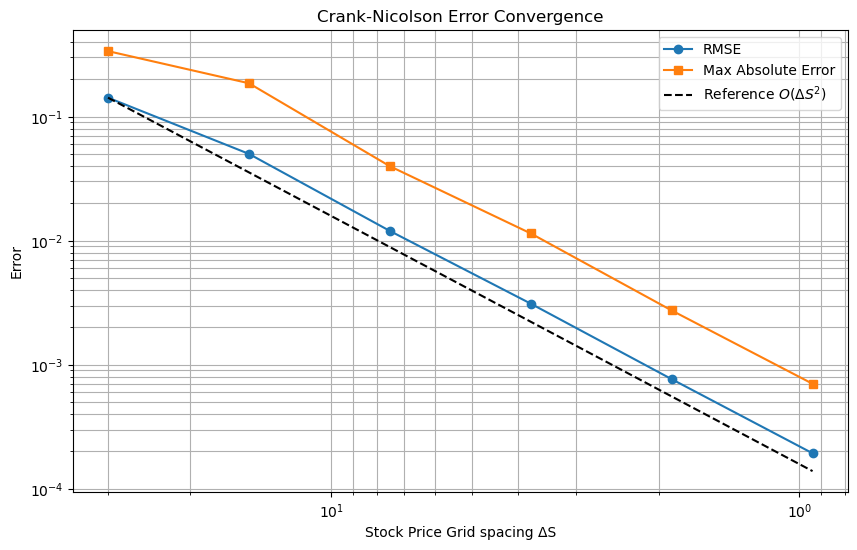

In [ ]:
plt.figure(figsize=(10, 6))

plt.loglog(
    results_df["dS"],
    results_df["RMSE"],
    marker="o",
    label="RMSE"
)

plt.loglog(
    results_df["dS"],
    results_df["Max Absolute Error"],
    marker="s",
    label="Max Absolute Error"
)

# Adding a reference line for O(ΔS^2) convergence rate.
reference = results_df["RMSE"].iloc[0] * (
    results_df["dS"] / results_df["dS"].iloc[0]
)**2

plt.loglog(
    results_df["dS"],
    reference,
    linestyle="--",
    color="black",
    label=r"Reference $O(\Delta S^2)$"
)

plt.xlabel("Stock Price Grid spacing ΔS")
plt.ylabel("Error")
plt.title("Crank-Nicolson Error Convergence")
plt.grid(which="both")
plt.legend()
plt.gca().invert_xaxis()
plt.show()

As the grid is refined clearly this Crank-Nicolson method converges. Both RMSE and Max Absolute Error both converge approximately in line with the second order convergence reference slope. 

In [ ]:
# Testing my error_summary function

from src.metrics import error_summary

results = error_summary(V, bs_values)
results

{'MSE': 0.02020530953563358,
 'RMSE': 0.14214538168942945,
 'MAE': 0.08475182561391843,
 'Max Abs Error': 0.3373211595694947,
 'Relative L2 Error': 0.0013742869882747866}